# 03 - Model Analysis

Reads the artifacts saved by `python -m src.pipeline` (stages 4 and 5) and interprets them. All numbers below are on the **held-out test set**, which was scored once in Phase 4. Nothing here changes the model or the threshold.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json
import pandas as pd
from IPython.display import Image, display

from src import config

M, F = config.METRICS_DIR, config.FIGURES_DIR
model = json.loads((M / "model_summary.json").read_text())
evals = json.loads((M / "evaluation_summary.json").read_text())
pd.set_option("display.width", 160)

def show(name, width=650):
    display(Image(filename=str(F / f"{name}.png"), width=width))

## 1. Model selection recap

In [2]:
cv = pd.read_csv(M / "cv_results.csv")
display(cv[["model", "features", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "recall_top10_mean"]].round(4))
tuned = json.loads((M / "tuning_results.json").read_text())
pd.DataFrame({n: {'cv_pr_auc': t['cv_pr_auc_mean'], 'val_pr_auc': t['val']['pr_auc'],
                  'features': t['best_params']['prep']} for n, t in tuned.items()}).T

,model,features,pr_auc_mean,pr_auc_std,roc_auc_mean,recall_top10_mean
0,logreg,raw,0.6636,0.0223,0.8468,0.2844
1,logreg,engineered,0.6629,0.0262,0.8475,0.2859
2,random_forest,engineered,0.6610,0.0226,0.8447,0.2768
3,random_forest,raw,0.6603,0.0288,0.8446,0.2844
4,xgboost,raw,0.6601,0.0265,0.8395,0.2898
5,xgboost,engineered,0.6492,0.0224,0.8362,0.2791
6,lightgbm,raw,0.6486,0.0210,0.8349,0.2829
7,lightgbm,engineered,0.6470,0.0177,0.8343,0.2859


,cv_pr_auc,val_pr_auc,features
logreg,0.664242,0.624407,raw
random_forest,0.66938,0.637608,raw
xgboost,0.671749,0.640956,raw


Untuned, the logistic regression baseline led cross-validation. After tuning, XGBoost had the best CV and validation PR-AUC, and was selected on validation. Every tuned model preferred raw features.

## 2. Test results: final model vs. baseline

In [3]:
rows = {who: model["test"][who] for who in ("final", "baseline")}
cols = ["pr_auc", "roc_auc", "recall_top10", "lift_top10", "brier", "threshold", "precision", "recall", "contact_rate", "profit"]
display(pd.DataFrame(rows).T[cols].round(4))
print("Bootstrap PR-AUC difference:", {k: round(v, 4) for k, v in model["test_pr_auc_diff_bootstrap"].items()})

,pr_auc,roc_auc,recall_top10,lift_top10,brier,threshold,precision,recall,contact_rate,profit
final,0.6713,0.8558,0.2929,2.9203,0.1590,0.58,0.5845,0.7286,0.3302,13150.0
baseline,0.6412,0.8492,0.2786,2.7778,0.1669,0.57,0.5412,0.7500,0.3671,12100.0


Bootstrap PR-AUC difference: {'diff': 0.0301, 'ci_low': 0.0035, 'ci_high': 0.0552, 'p_a_better': 0.985}


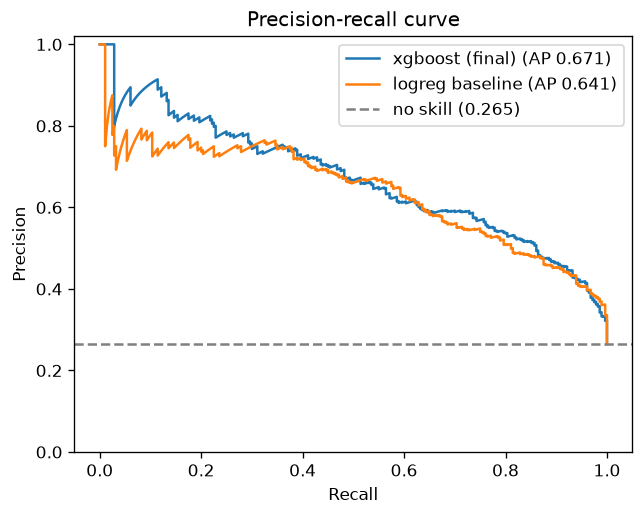

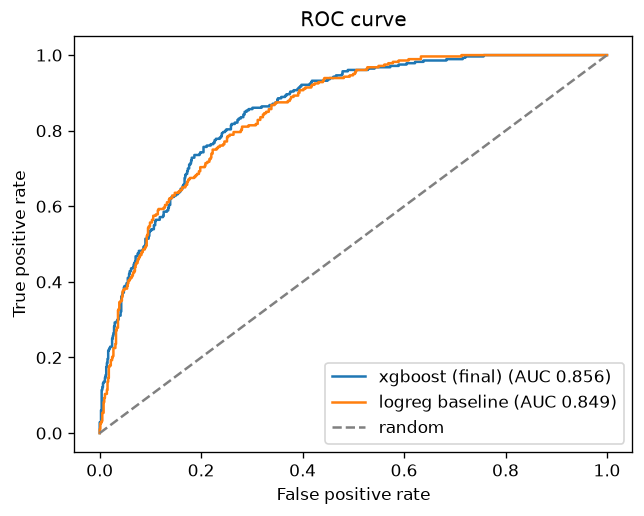

In [4]:
show("eval_pr_curve", 520); show("eval_roc_curve", 520)

**Finding:** the final model's precision-recall curve sits above the baseline across most recall levels. The PR-AUC gain is +0.030 with a 95% bootstrap CI of [+0.003, +0.055], so the improvement is real but modest. ROC-AUC differs by under 0.01.

## 3. Targeting: gain and lift

,decile,customers,churners,min_score,churn_rate,lift,cum_customers_pct,cum_churners_pct
0,1,106,82,0.783,0.774,2.920,0.100,0.293
1,2,106,60,0.708,0.566,2.137,0.201,0.507
2,3,106,46,0.610,0.434,1.638,0.301,0.671
3,4,105,37,0.511,0.352,1.330,0.400,0.804
4,5,106,24,0.398,0.226,0.855,0.500,0.889
5,6,106,16,0.290,0.151,0.570,0.601,0.946
6,7,105,8,0.201,0.076,0.288,0.700,0.975
7,8,106,6,0.118,0.057,0.214,0.800,0.996
8,9,106,1,0.095,0.009,0.036,0.901,1.000
9,10,105,0,0.074,0.000,0.000,1.000,1.000


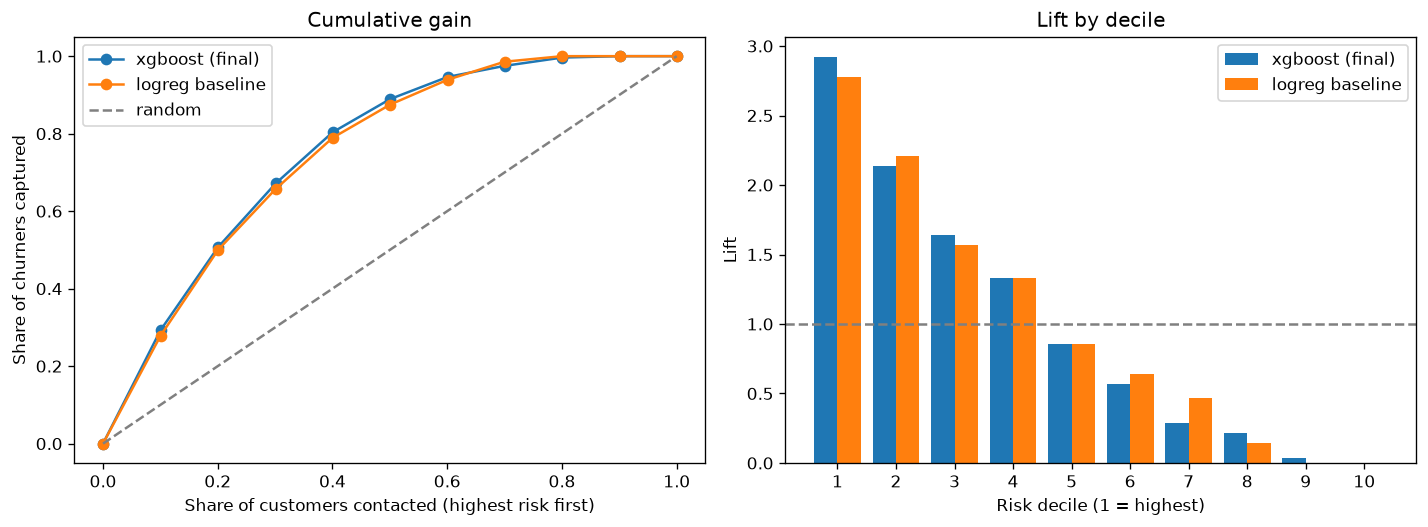

In [5]:
display(pd.read_csv(M / "gain_table.csv").round(3))
show("eval_gain_lift", 900)

**Finding:** ranking is where this model earns its keep.
- The top 10% riskiest customers churn at **77%** (lift 2.9).
- Contacting the top 30% reaches **67%** of all churners; the top 50% reaches **89%**.
- The bottom 30% contains only 7 churners out of 317 customers, so they can safely be left out of retention campaigns.

## 4. Decision threshold

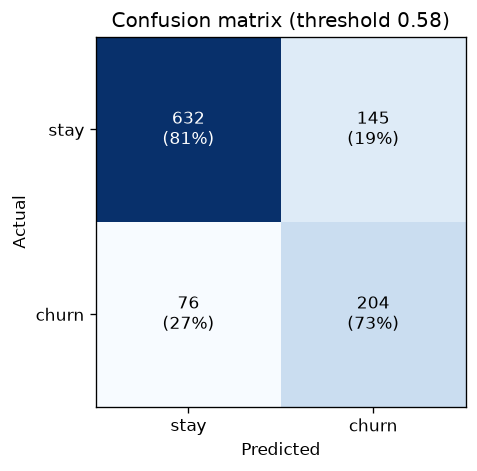

In [6]:
show("eval_confusion_matrix", 420)

At the profit-maximizing threshold of **0.58** (chosen on validation), the model contacts about a third of customers, catches **73%** of churners, and about **58%** of contacted customers are real churners. The threshold depends on the placeholder costs in `src/config.py` (offer 50, retained value 500, success rate 30%).

## 5. Calibration

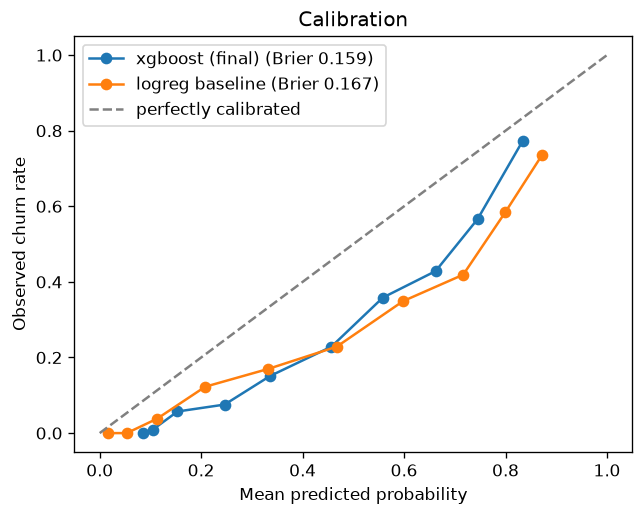

,mean_predicted,observed_rate,ece
xgboost (final),0.4182,0.2649,0.1534
logreg baseline,0.4176,0.2649,0.1528


In [7]:
show("eval_calibration", 520)
pd.DataFrame(evals["calibration"]).T.round(4)

**Finding: the probabilities are inflated.** Both models predict about **42%** churn on average while the true rate is **26.5%** (expected calibration error 0.15). Class weighting causes this: the models are trained as if churners were as common as stayers.

- **Ranking is unaffected**, so PR-AUC, lift and the customer ranking are all valid.
- **The threshold is still valid**, because it was tuned on real validation outcomes, not on the probability values.
- **Raw scores should not be shown as "probability of churn"** without calibration. This affects the Phase 6 ranked list.

## 6. Performance by segment

In [8]:
seg = pd.read_csv(M / "segment_performance.csv")
seg.round(3)

,segment,value,customers,churn_rate,mean_score,pr_auc,roc_auc
0,Contract,Month-to-month,583,0.424,0.608,0.703,0.767
1,Contract,One year,224,0.125,0.245,0.343,0.759
2,Contract,Two year,250,0.020,0.131,0.080,0.868
3,tenure_band,0-6,225,0.573,0.668,0.808,0.766
4,tenure_band,13-24,154,0.292,0.499,0.634,0.812
5,tenure_band,25-48,239,0.213,0.350,0.528,0.803
6,tenure_band,49+,337,0.077,0.227,0.447,0.891
7,tenure_band,7-12,102,0.284,0.535,0.514,0.749
8,InternetService,DSL,358,0.184,0.342,0.581,0.837
9,InternetService,Fiber optic,480,0.412,0.582,0.719,0.791


**Finding:** the model separates risky groups from safe groups easily, but is weaker *within* the riskiest groups:
- Month-to-month customers (42% churn): ROC-AUC **0.77**, against 0.86 overall.
- New customers (0-6 months, 57% churn): ROC-AUC **0.77**.
- Safe segments (two-year contracts, 49+ months tenure, no internet) score 0.87-0.91, but those segments have few churners anyway.

Telling *which* month-to-month customer will leave needs behavioral signals the dataset lacks (usage trends, support contacts, payment failures). This is the main lever for a better model in production.

## 7. What drives churn: global SHAP

,feature,mean_abs_shap,share
0,Contract,0.7128,0.3365
1,tenure,0.2500,0.1180
2,InternetService,0.2087,0.0985
3,MonthlyCharges,0.1767,0.0834
4,OnlineSecurity,0.1636,0.0772
5,TechSupport,0.1433,0.0676
6,PaymentMethod,0.1036,0.0489
7,TotalCharges,0.1018,0.0481
8,PaperlessBilling,0.0610,0.0288
9,StreamingMovies,0.0473,0.0224


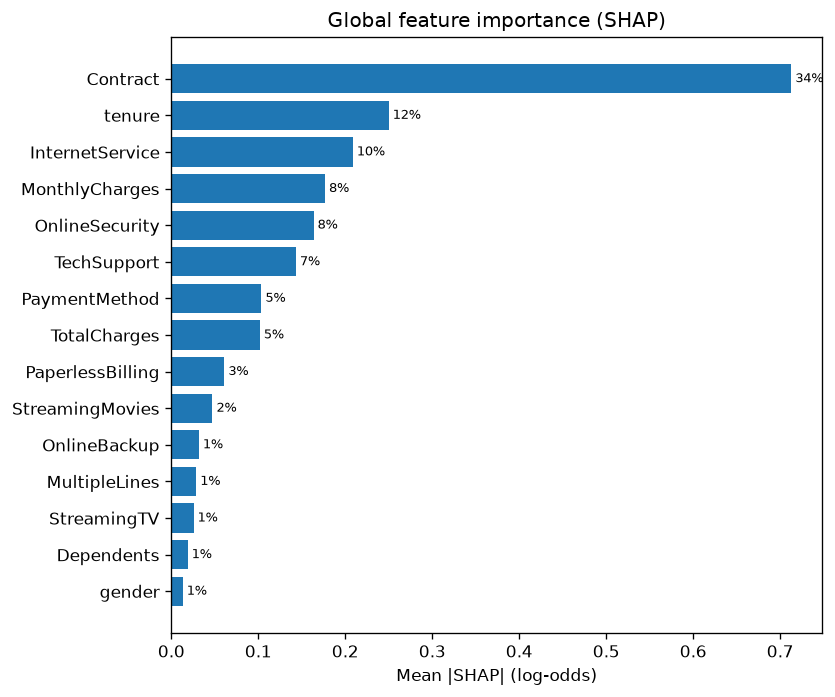

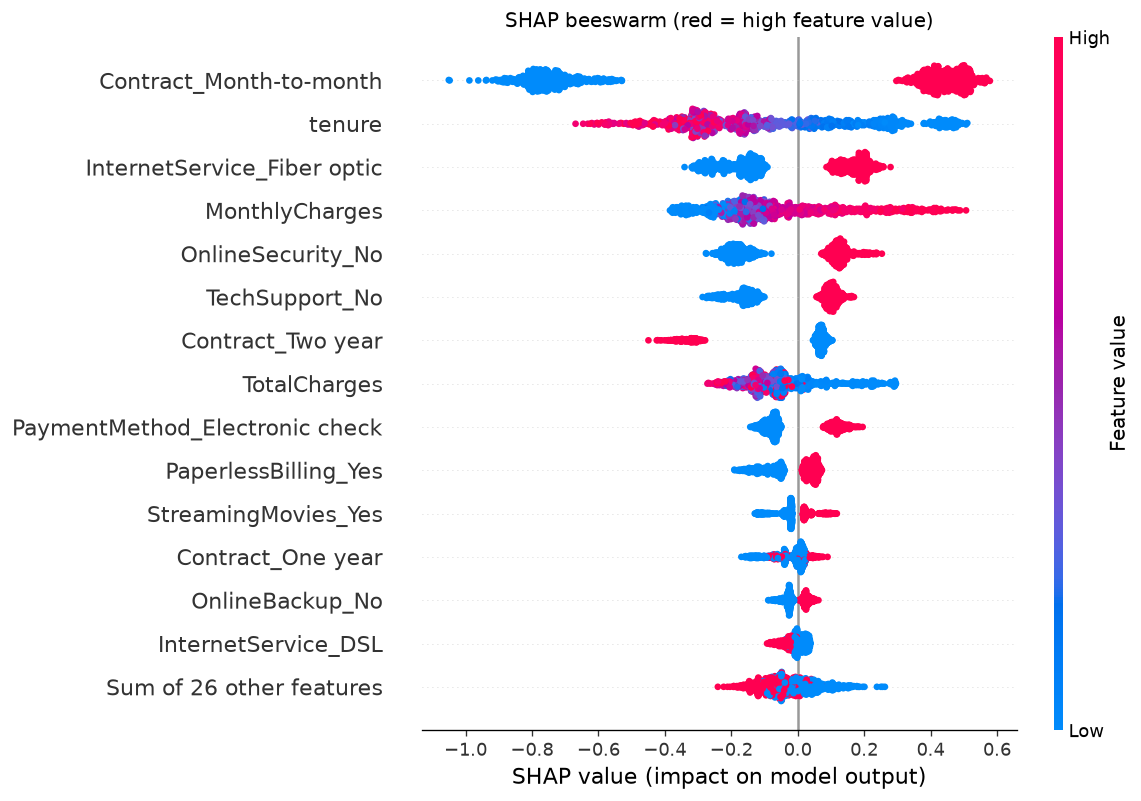

In [9]:
display(pd.read_csv(M / "shap_importance.csv").round(4).head(12))
show("shap_global_importance", 560)
show("shap_beeswarm", 720)

**Findings** (SHAP on the test set, one-hot columns summed per original feature):
- **Contract** accounts for about a third of all attribution. Month-to-month pushes risk up strongly; two-year contracts push it down the most.
- **Tenure** is second: risk is highest in the first months and falls steadily.
- **Fiber optic** internet and **higher monthly charges** raise risk.
- **No OnlineSecurity / TechSupport** raises risk, matching the EDA (about 42% vs 15% churn).
- **Electronic check** payment and **paperless billing** add smaller increases.
- **gender**, **Partner**, **Dependents** and **PhoneService** contribute almost nothing.
- **SeniorCitizen** churned at 42% in the EDA but gets only about 0.5% of attribution. Seniors' extra risk is explained by their contracts, services and charges, not by age itself, which matters for how retention offers are targeted.

## 8. Per-customer explanations

high_risk   5178-LMXOP  p=0.89  actual=1  reasons=['Contract = Month-to-month', 'tenure = 1 month', 'InternetService = Fiber optic']
borderline  6227-HWPWX  p=0.58  actual=1  reasons=['Contract = Month-to-month', 'InternetService = Fiber optic', 'OnlineSecurity = No']
low_risk    0794-YVSGE  p=0.07  actual=0  reasons=[]


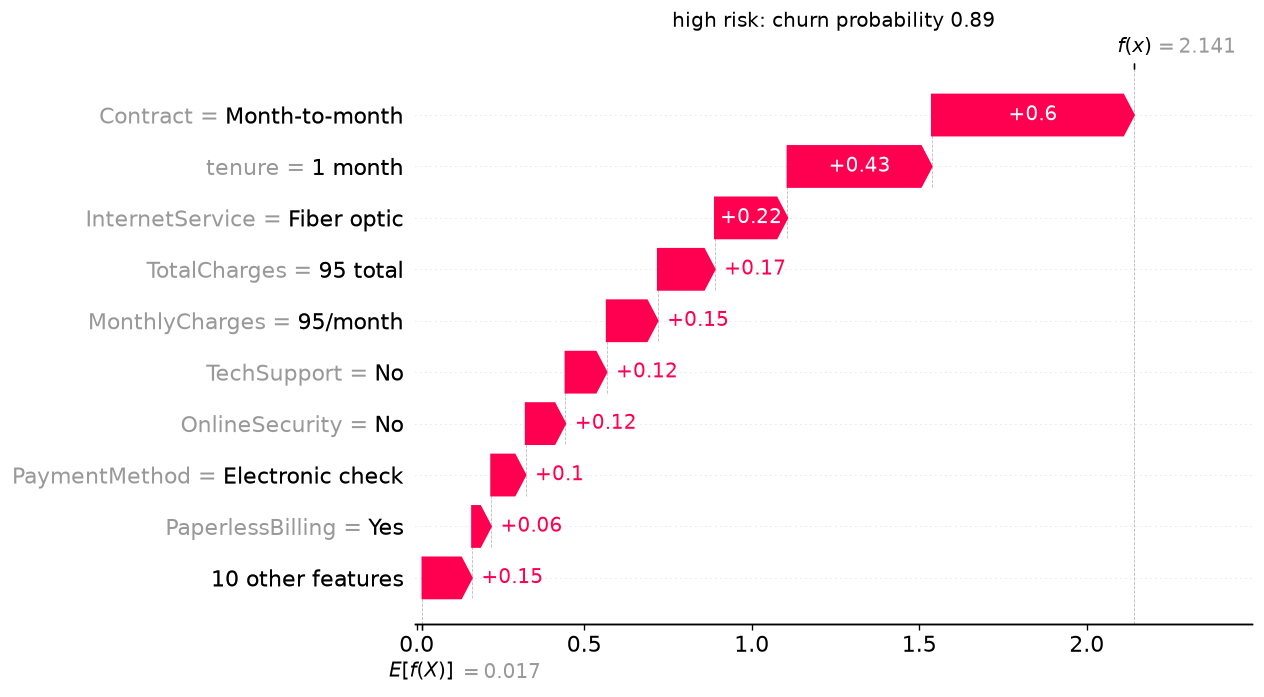

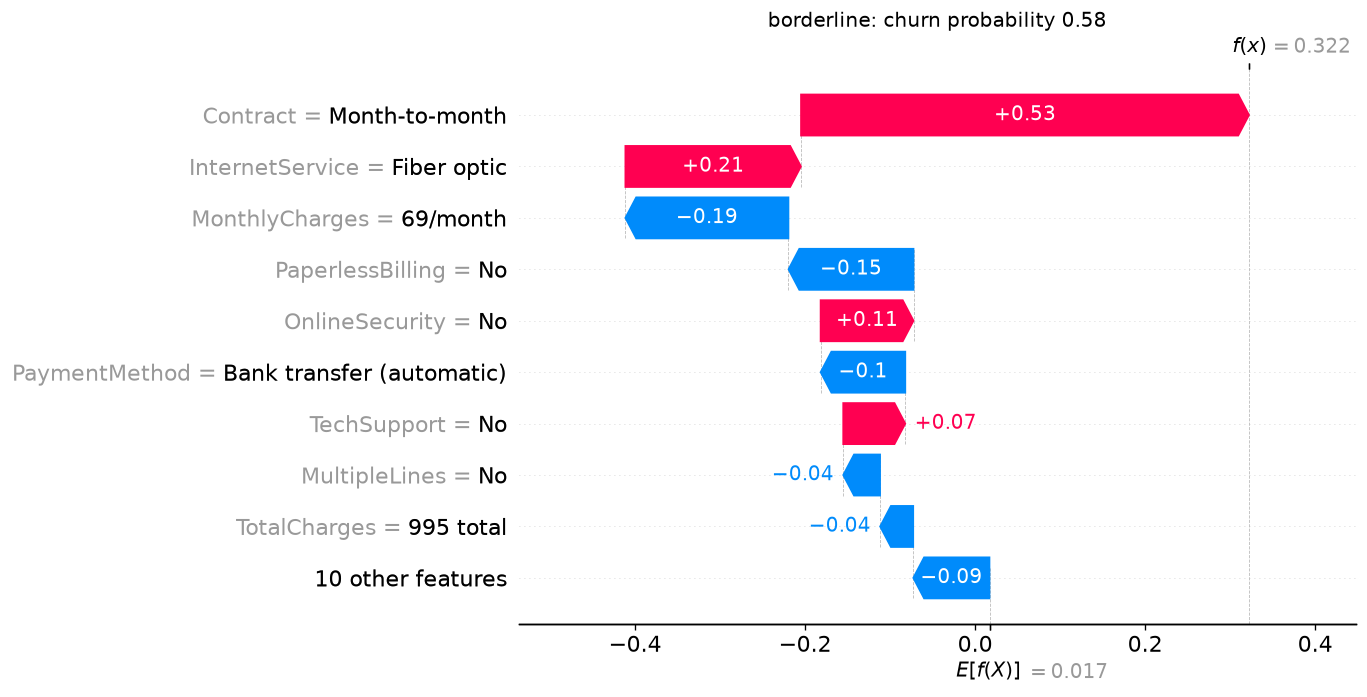

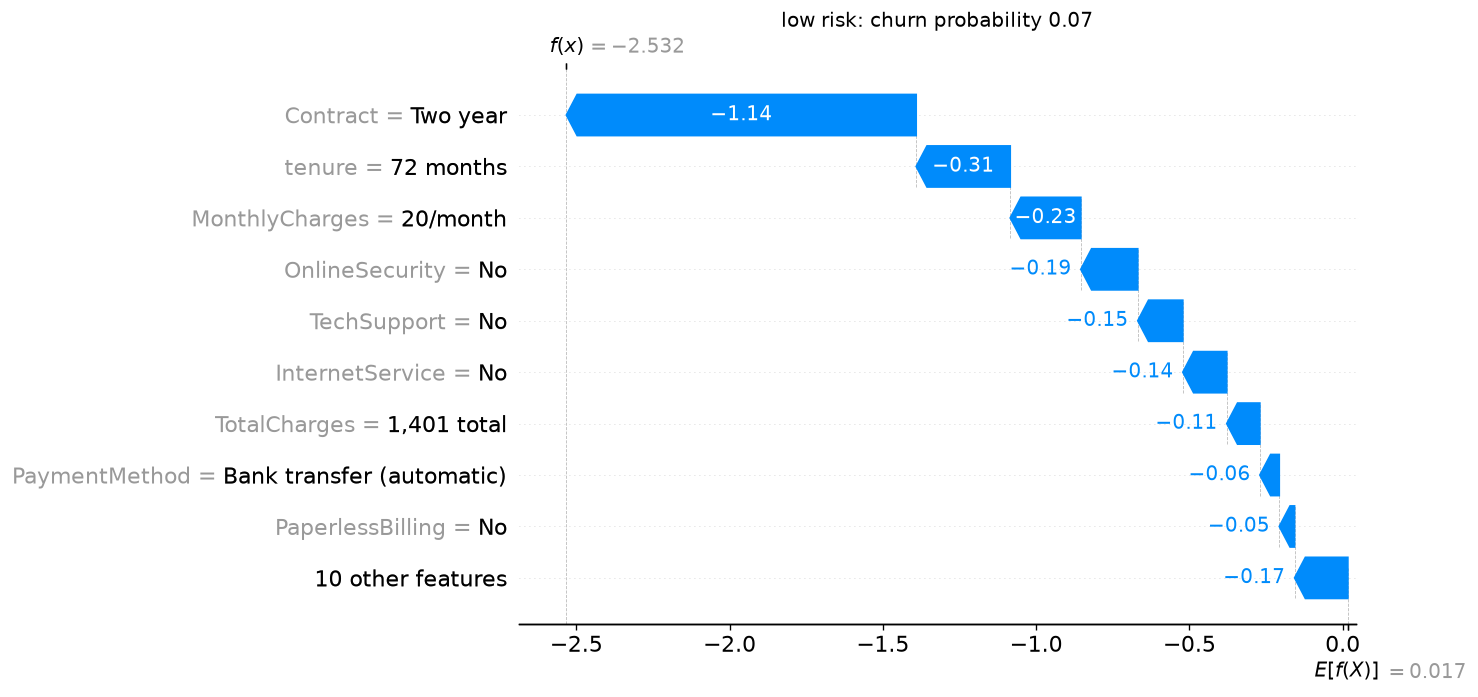

In [10]:
for label, info in evals["example_customers"].items():
    print(f"{label:<11} {info['customer_id']}  p={info['probability']:.2f}  "
          f"actual={info['actual_churn']}  reasons={info['top_reasons']}")
for label in ("high_risk", "borderline", "low_risk"):
    show(f"shap_customer_{label}", 760)

Each customer's SHAP values add up exactly to their prediction (in log-odds). Phase 6 uses the same `top_reasons` function to attach the top 3 risk drivers to every customer in the ranked list. The low-risk example has no risk-increasing factors, so it has no reasons listed.

## 9. Summary

| Question | Answer |
|---|---|
| Does the final model beat the baseline? | Yes: PR-AUC 0.671 vs 0.641, 95% CI of gain [+0.003, +0.055] |
| How useful is the ranking? | Top 10% churn at 77% (lift 2.9); top 30% hold 67% of churners |
| Can the scores be read as probabilities? | **No, not yet**: they over-predict by about 15 points on average |
| Where is the model weakest? | Inside month-to-month and new-customer segments |
| What drives churn? | Contract type, short tenure, fiber internet, high charges, no security/support add-ons |

**Open decision for Phase 6:** calibrate the probabilities (for example, isotonic calibration fit on validation) before publishing the ranked customer list.